In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('student_performance_complete.csv')
df.head()

,student_id,department,study_hours,attendance_pct,previous_score,marks,passed
0,S001,SE,5.5,84.7,82.9,90.4,Yes
1,S002,CS,5.0,73.4,36.9,66.8,Yes
2,S003,Cybersecurity,5.8,80.5,57.8,70.9,Yes
3,S004,SE,7.8,80.5,46.1,85.4,Yes
4,S005,AI,5.6,85.8,57.3,89.6,Yes


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      180 non-null    str    
 1   department      180 non-null    str    
 2   study_hours     180 non-null    float64
 3   attendance_pct  180 non-null    float64
 4   previous_score  180 non-null    float64
 5   marks           180 non-null    float64
 6   passed          180 non-null    str    
dtypes: float64(4), str(3)
memory usage: 10.0 KB


In [3]:
df.describe()


,study_hours,attendance_pct,previous_score,marks
count,180.000000,180.000000,180.000000,180.000000
mean,5.294444,81.749444,66.134444,79.513889
std,2.021746,9.842114,13.096630,10.946093
min,0.500000,52.400000,34.700000,48.500000
25%,3.975000,75.175000,57.000000,71.700000
50%,5.300000,82.300000,65.750000,79.750000
75%,6.500000,88.475000,75.000000,87.500000
max,11.000000,100.000000,100.000000,100.000000


In [4]:
df.isna().sum()

student_id        0
department        0
study_hours       0
attendance_pct    0
previous_score    0
marks             0
passed            0
dtype: int64

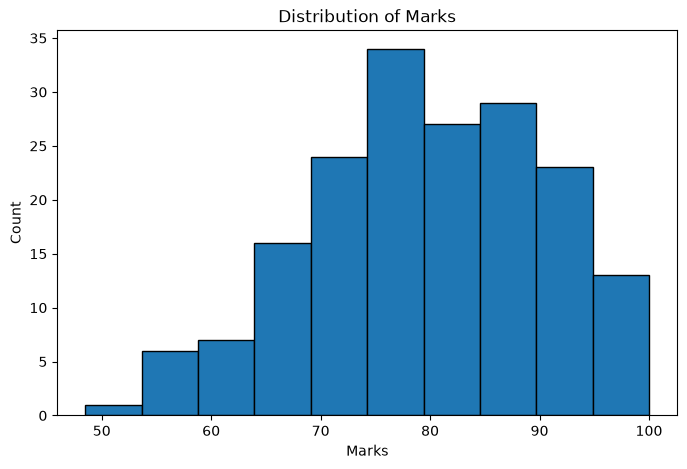

In [5]:
plt.figure(figsize=(8,5))
plt.hist(df['marks'], bins=10, edgecolor='black')
plt.title("Distribution of Marks")
plt.xlabel("Marks"); plt.ylabel("Count")
plt.show()

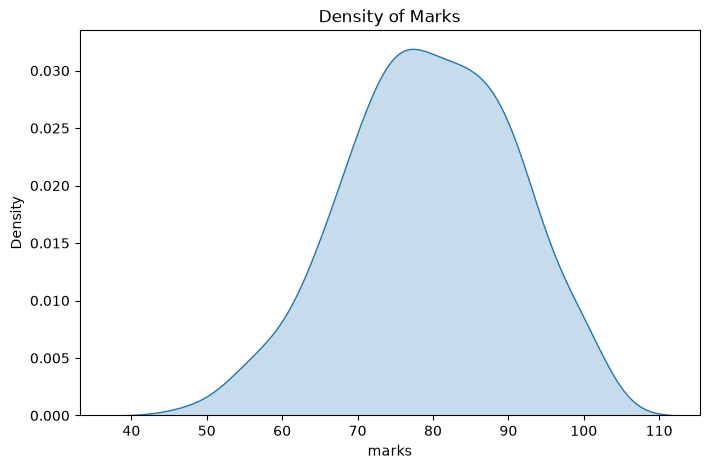

In [6]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=df, x='marks', fill=True)
plt.title("Density of Marks")
plt.show()

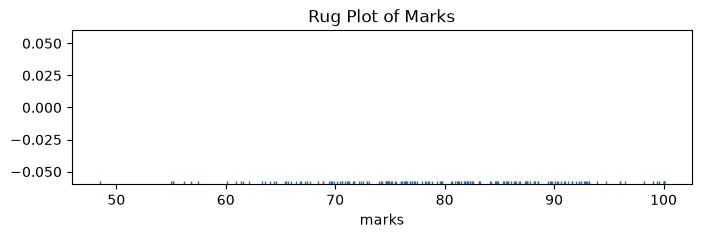

In [7]:
plt.figure(figsize=(8,2))
sns.rugplot(data=df, x='marks')
plt.title("Rug Plot of Marks")
plt.show()

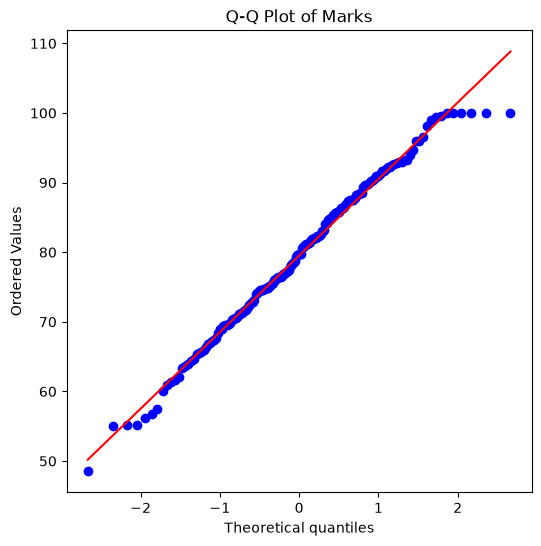

In [8]:
plt.figure(figsize=(6,6))
stats.probplot(df['marks'], dist='norm', plot=plt)
plt.title("Q-Q Plot of Marks")
plt.show()

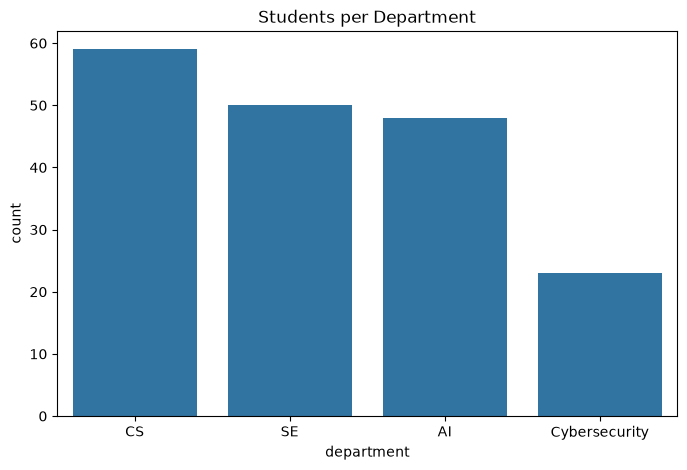

In [9]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='department', order=df['department'].value_counts().index)
plt.title("Students per Department")
plt.show()

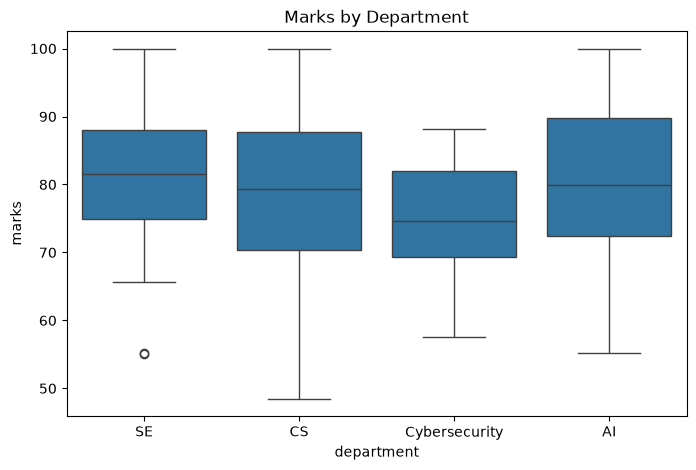

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='department', y='marks')
plt.title("Marks by Department")
plt.show()

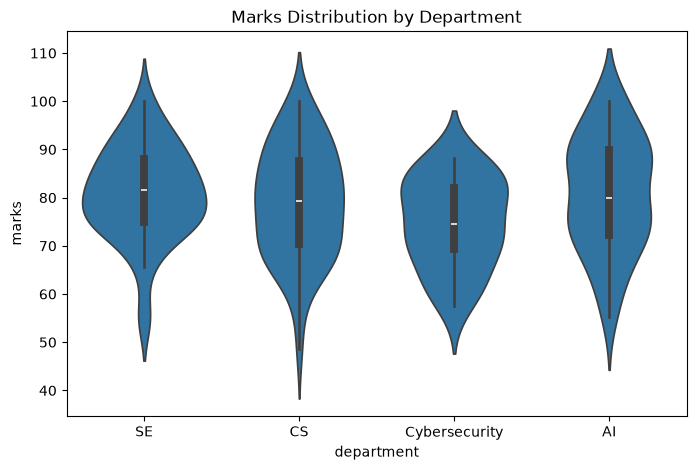

In [11]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='department', y='marks')
plt.title("Marks Distribution by Department")
plt.show()

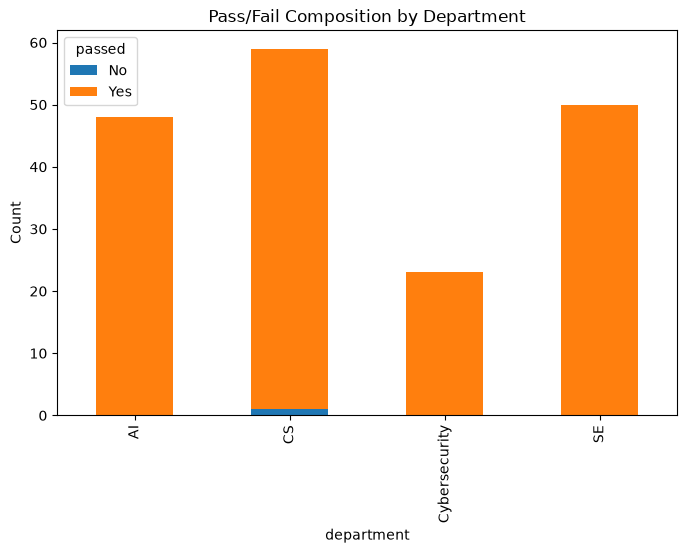

In [13]:
dept_pass = pd.crosstab(df['department'], df['passed'])
dept_pass.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title("Pass/Fail Composition by Department")
plt.ylabel("Count")
plt.show()

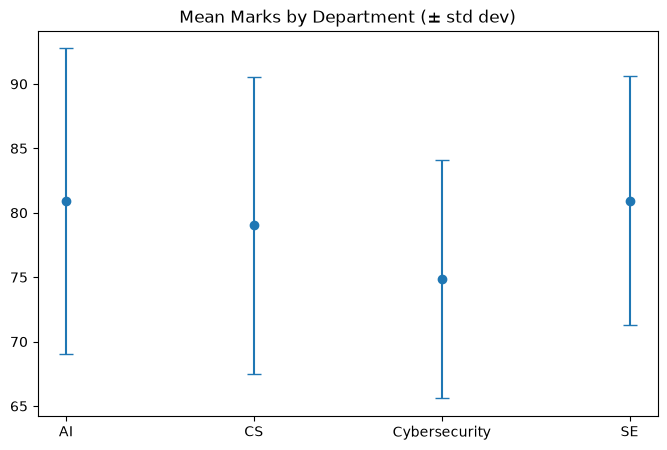

In [14]:
means = df.groupby('department')['marks'].mean()
stds = df.groupby('department')['marks'].std()
plt.figure(figsize=(8,5))
plt.errorbar(means.index, means.values, yerr=stds.values, fmt='o', capsize=5)
plt.title("Mean Marks by Department (± std dev)")
plt.show()

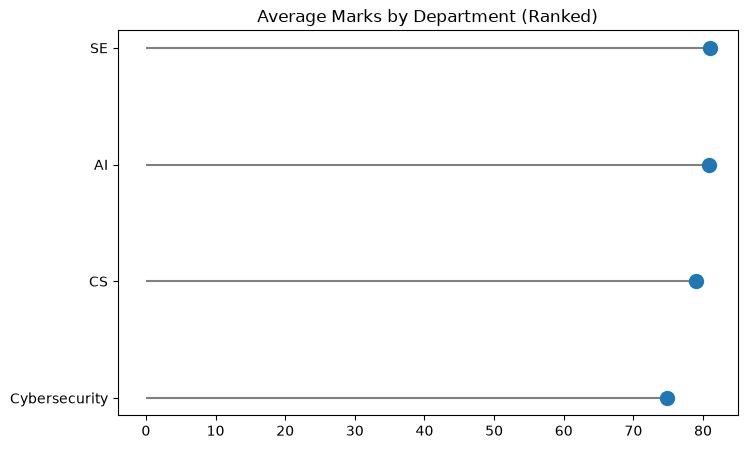

In [15]:
means_sorted = df.groupby('department')['marks'].mean().sort_values()
plt.figure(figsize=(8,5))
plt.hlines(means_sorted.index, 0, means_sorted.values, color='gray')
plt.plot(means_sorted.values, means_sorted.index, 'o', markersize=10)
plt.title("Average Marks by Department (Ranked)")
plt.show()

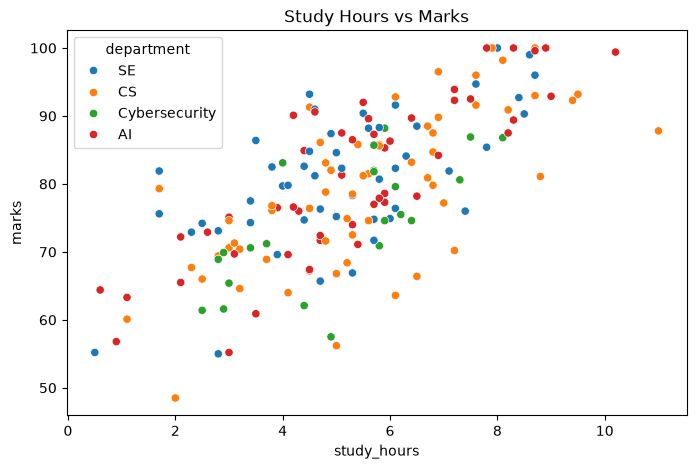

In [16]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='study_hours', y='marks', hue='department')
plt.title("Study Hours vs Marks")
plt.show()

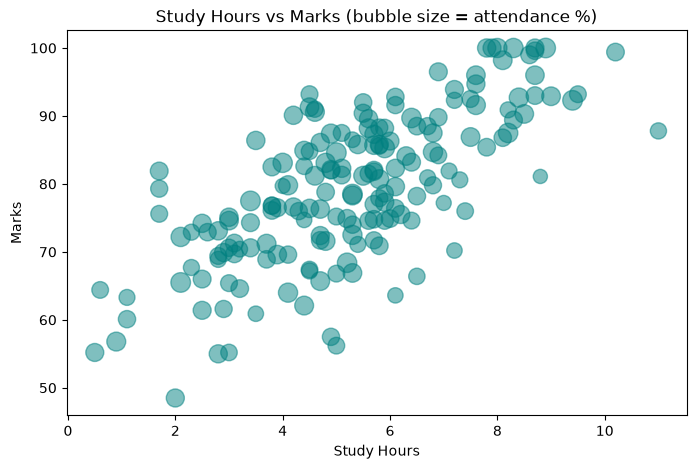

In [17]:
plt.figure(figsize=(8,5))
plt.scatter(df['study_hours'], df['marks'], s=df['attendance_pct']*2, alpha=0.5, c='teal')
plt.title("Study Hours vs Marks (bubble size = attendance %)")
plt.xlabel("Study Hours"); plt.ylabel("Marks")
plt.show()

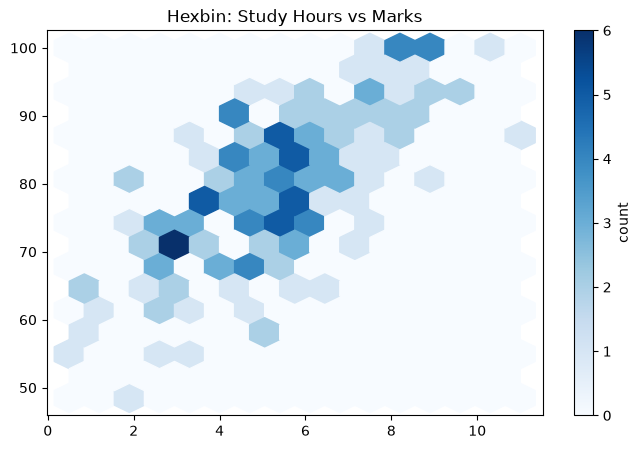

In [18]:
plt.figure(figsize=(8,5))
plt.hexbin(df['study_hours'], df['marks'], gridsize=15, cmap='Blues')
plt.colorbar(label='count')
plt.title("Hexbin: Study Hours vs Marks")
plt.show()

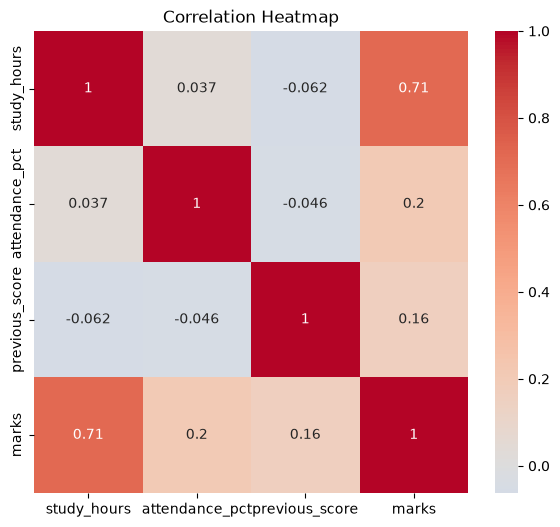

In [19]:
plt.figure(figsize=(7,6))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

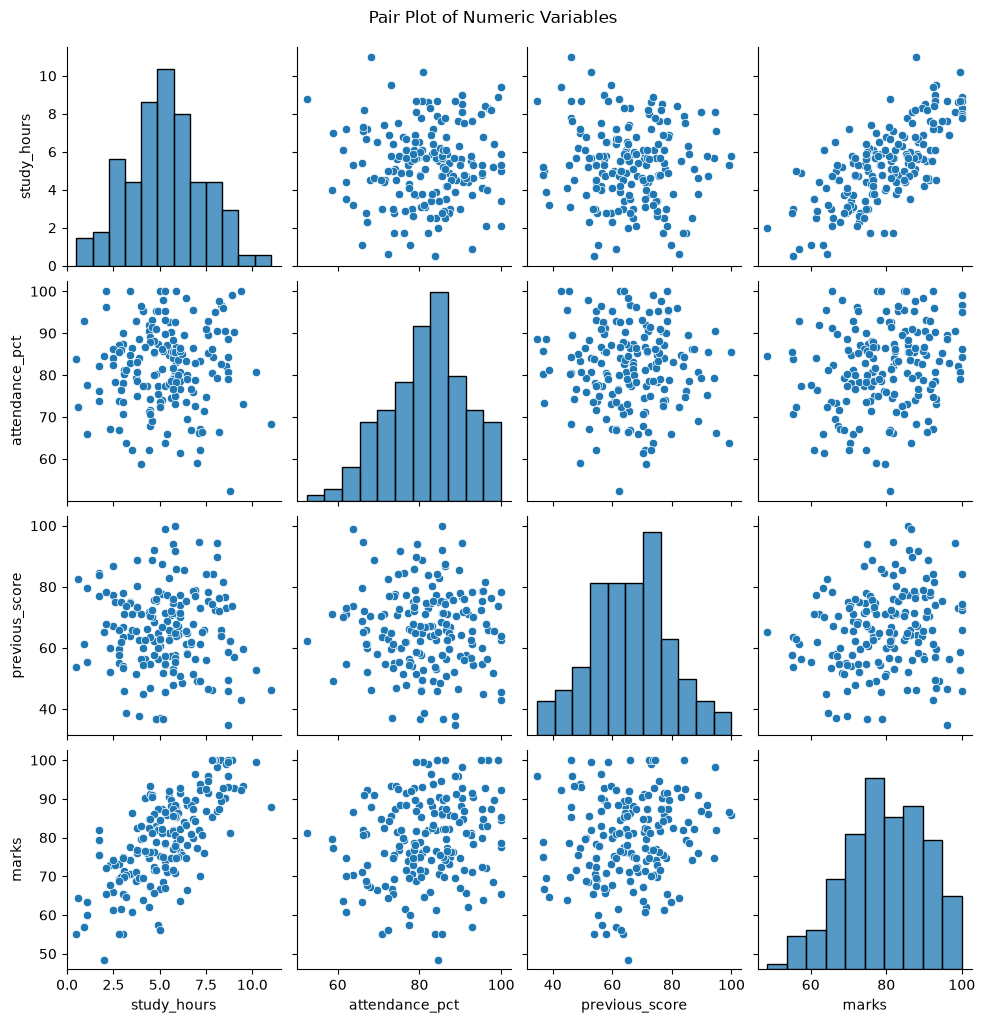

In [20]:
sns.pairplot(df[['study_hours','attendance_pct','previous_score','marks']])
plt.suptitle("Pair Plot of Numeric Variables", y=1.02)
plt.show()

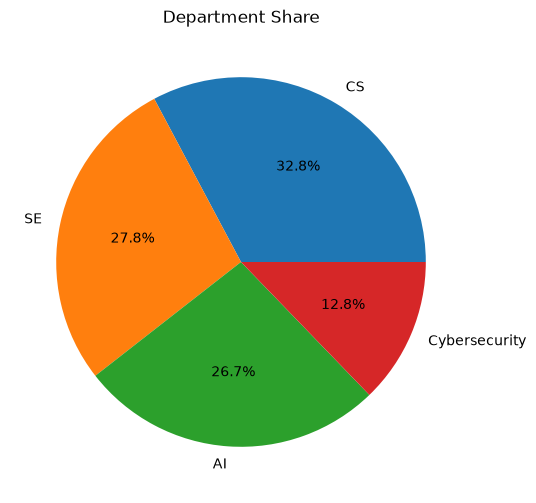

In [21]:
dept_counts = df['department'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(dept_counts.values, labels=dept_counts.index, autopct='%1.1f%%')
plt.title("Department Share")
plt.show()

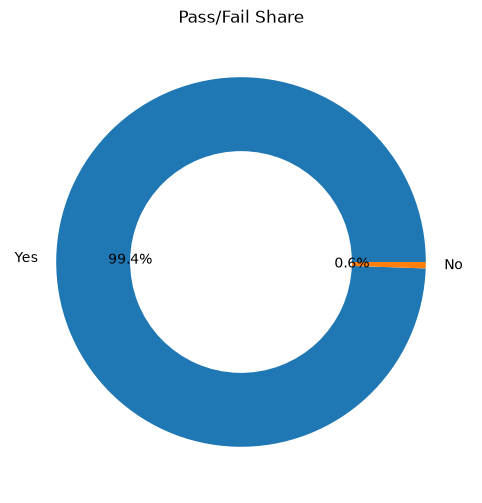

In [22]:
pass_counts = df['passed'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(pass_counts.values, labels=pass_counts.index, autopct='%1.1f%%', wedgeprops={'width':0.4})
plt.title("Pass/Fail Share")
plt.show()

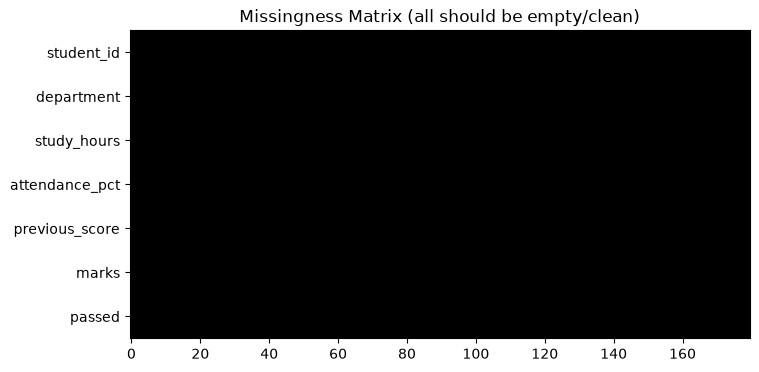

In [23]:
plt.figure(figsize=(8,4))
plt.imshow(df.isna().T, aspect='auto', cmap='gray')
plt.yticks(range(len(df.columns)), df.columns)
plt.title("Missingness Matrix (all should be empty/clean)")
plt.show()

In [24]:
import plotly.express as px
fig = px.scatter(df, x='study_hours', y='marks', color='department', hover_data=['student_id'])
fig.show()

In [25]:
df.select_dtypes(include='number').corr()

,study_hours,attendance_pct,previous_score,marks
study_hours,1.000000,0.036591,-0.062420,0.709754
attendance_pct,0.036591,1.000000,-0.046015,0.204943
previous_score,-0.062420,-0.046015,1.000000,0.158365
marks,0.709754,0.204943,0.158365,1.000000


## Five Findings

1. **Study hours is the strongest predictor of marks.** Correlation = 0.71 — by far the highest of any variable. More hours studied clearly tracks with higher marks.

2. **Attendance and previous score barely matter.** Attendance correlates only 0.20 with marks, and previous score only 0.16 — both weak. Showing up and past performance don't predict current marks nearly as much as study hours does.

3. **Cybersecurity students score lowest on average.** Mean marks: Cybersecurity 74.8, CS 79.0, AI 80.9, SE 80.9. Cybersecurity is noticeably behind the other three departments.

4. **Marks are roughly normal, slightly left-skewed.** Mean (79.5) and median (79.8) are almost equal, skewness is only -0.20 (close to 0) — no major outliers pulling the distribution one way.

5. **Pass/fail is not a useful variable to analyze.** 179 out of 180 students passed — only 1 failed (in CS). With almost no variation, comparing pass rates across departments or plots won't reveal anything meaningful.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

retail = pd.read_csv("retail_sales_complete.csv", parse_dates=['date'])
sensor = pd.read_csv("pipeline_sensor_timeseries_complete.csv", parse_dates=['timestamp'])

retail.head()

,date,region,product,units_sold,unit_price,discount_pct,sales_revenue,customer_rating
0,2025-01-01,North,Monitor,5,223.84,20,895.38,3.2
1,2025-01-02,East,Monitor,4,251.58,10,905.70,4.2
2,2025-01-03,West,Laptop,6,889.73,5,5071.46,4.1
3,2025-01-04,North,Tablet,5,310.15,0,1550.73,4.4
4,2025-01-05,South,Keyboard,6,48.47,0,290.84,4.4


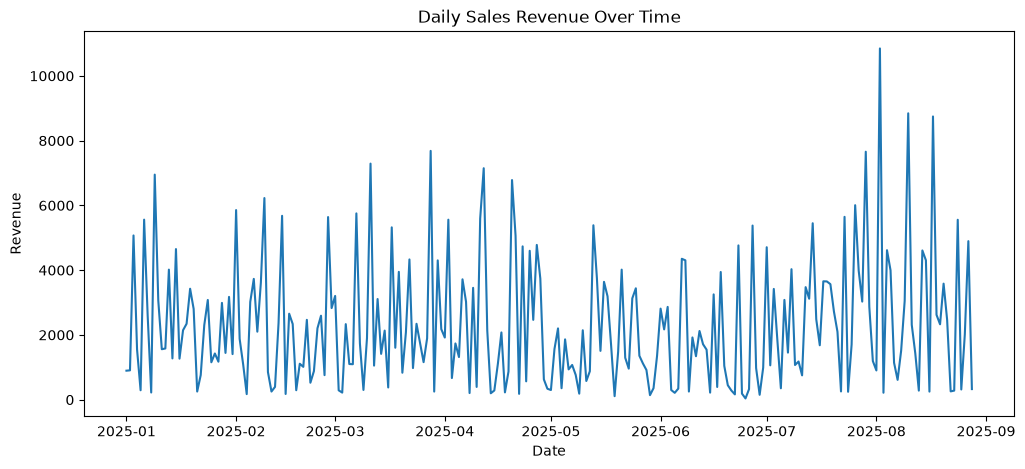

In [2]:
daily_sales = retail.groupby('date')['sales_revenue'].sum().sort_index()

plt.figure(figsize=(12,5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Sales Revenue Over Time")
plt.xlabel("Date"); plt.ylabel("Revenue")
plt.show()

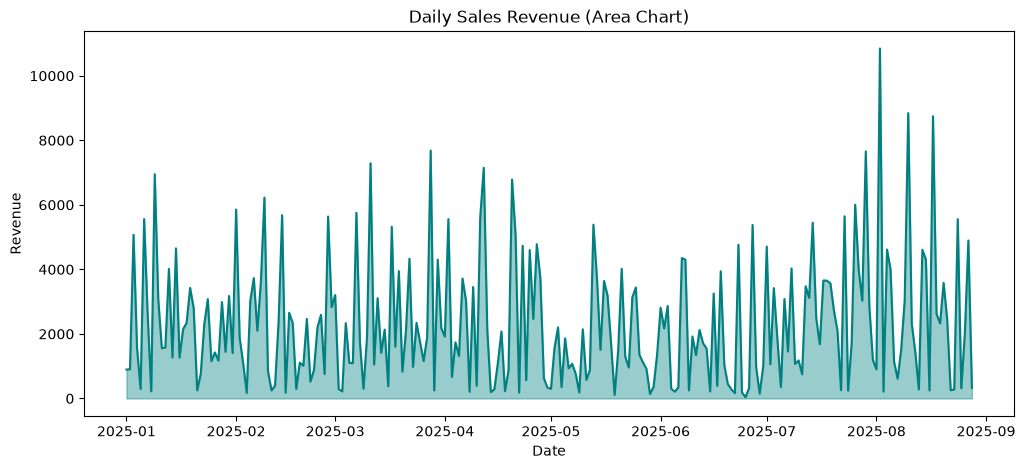

In [3]:
plt.figure(figsize=(12,5))
plt.fill_between(daily_sales.index, daily_sales.values, alpha=0.4, color='teal')
plt.plot(daily_sales.index, daily_sales.values, color='teal')
plt.title("Daily Sales Revenue (Area Chart)")
plt.xlabel("Date"); plt.ylabel("Revenue")
plt.show()

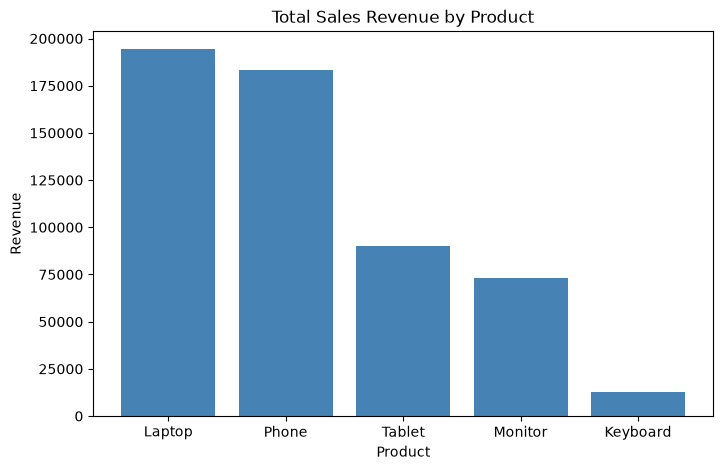

In [4]:
product_sales = retail.groupby('product')['sales_revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(product_sales.index, product_sales.values, color='steelblue')
plt.title("Total Sales Revenue by Product")
plt.xlabel("Product"); plt.ylabel("Revenue")
plt.show()

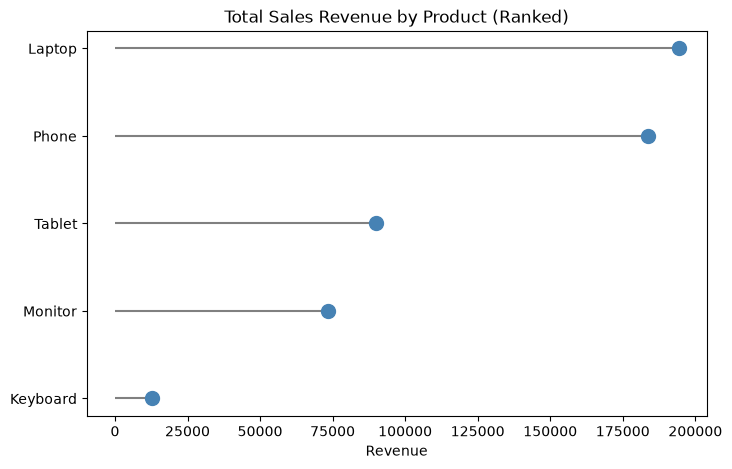

In [5]:
product_sales_sorted = product_sales.sort_values()

plt.figure(figsize=(8,5))
plt.hlines(product_sales_sorted.index, 0, product_sales_sorted.values, color='gray')
plt.plot(product_sales_sorted.values, product_sales_sorted.index, 'o', markersize=10, color='steelblue')
plt.title("Total Sales Revenue by Product (Ranked)")
plt.xlabel("Revenue")
plt.show()

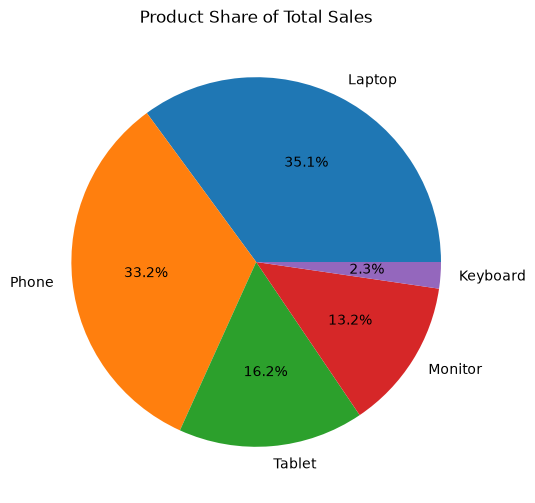

In [6]:
plt.figure(figsize=(6,6))
plt.pie(product_sales.values, labels=product_sales.index, autopct='%1.1f%%')
plt.title("Product Share of Total Sales")
plt.show()

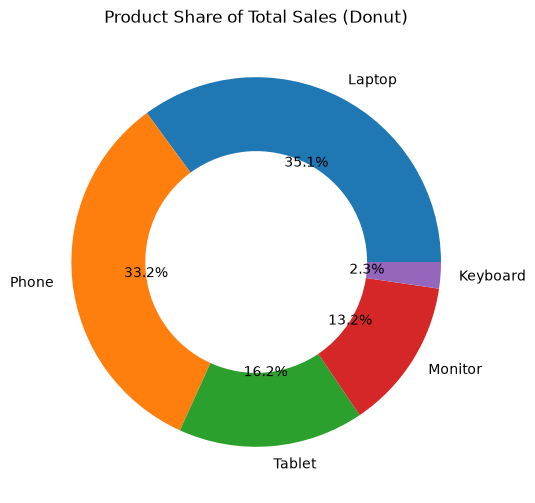

In [7]:
plt.figure(figsize=(6,6))
plt.pie(product_sales.values, labels=product_sales.index, autopct='%1.1f%%', wedgeprops={'width':0.4})
plt.title("Product Share of Total Sales (Donut)")
plt.show()

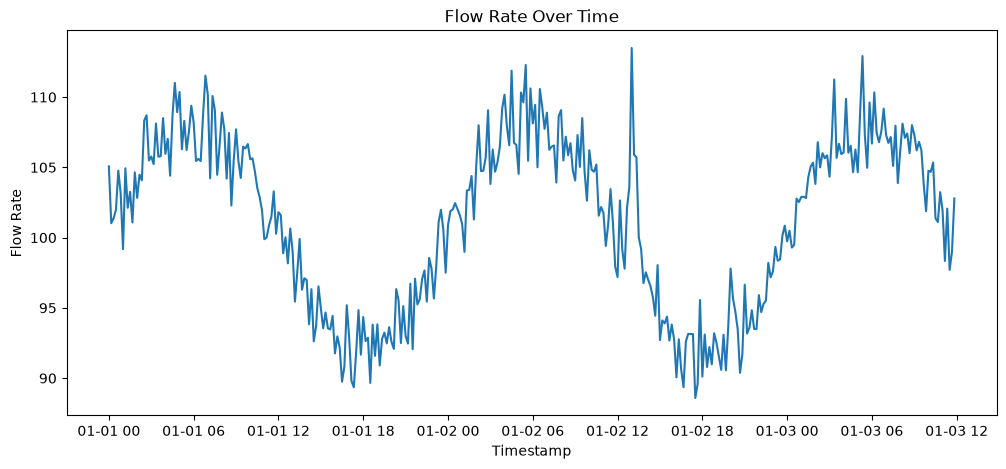

In [8]:
plt.figure(figsize=(12,5))
plt.plot(sensor['timestamp'], sensor['flow_rate'])
plt.title("Flow Rate Over Time")
plt.xlabel("Timestamp"); plt.ylabel("Flow Rate")
plt.show()

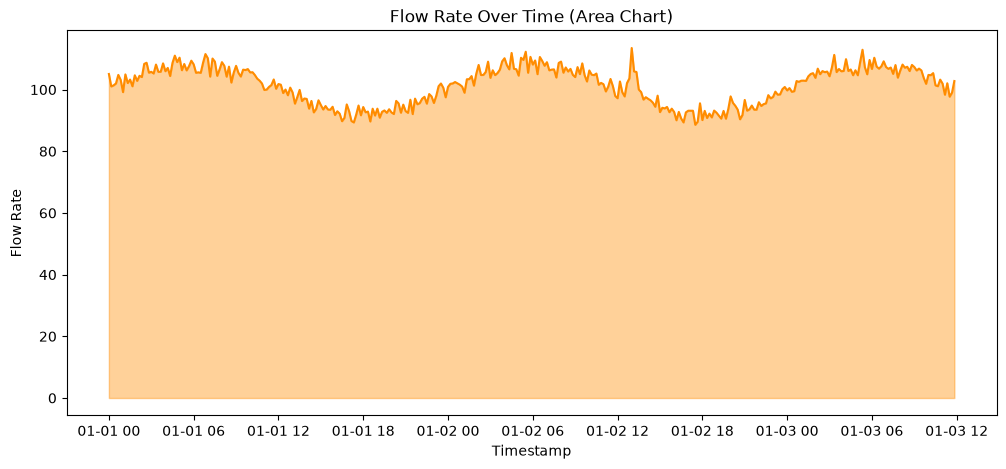

In [9]:
plt.figure(figsize=(12,5))
plt.fill_between(sensor['timestamp'], sensor['flow_rate'], alpha=0.4, color='darkorange')
plt.plot(sensor['timestamp'], sensor['flow_rate'], color='darkorange')
plt.title("Flow Rate Over Time (Area Chart)")
plt.xlabel("Timestamp"); plt.ylabel("Flow Rate")
plt.show()

In [10]:
import plotly.express as px

fig = px.line(daily_sales.reset_index(), x='date', y='sales_revenue',
              title="Daily Sales Revenue (Interactive)")
fig.show()

## Why Bars Are Easier to Compare Than Pie/Donut Charts

A bar chart lines up values against a common baseline (zero), so your eye compares **bar heights** — a simple, accurate visual task.

A pie/donut chart asks your eye to compare **angles and areas** of wedges, which humans are much worse at judging precisely. Two wedges that are close in size (e.g., Monitor vs Tablet here) are hard to rank just by looking, whereas their bar-chart heights make the difference obvious immediately.

**Rule of thumb:** Pie/donut charts work fine for a small number of categories where one is clearly dominant, but bar charts are more reliable whenever precise ranking or comparison between close values matters.